# COU 07506 — Digital Signal Processing
## Week 01 — Lab 0: Setting Up the DSP Laboratory

**Name:** Frolian Kato Kazaura  
**Registration:** 240242408359  
**Stream:** 4 
**Course:** Bachelor in Engineering in Computer Engineering  
**Date:** 24 November 2026

## Pre-lab

Today I used: My phone — when I recorded a voice note, it processed the microphone audio.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

## Task 1.1 — Your first notebook


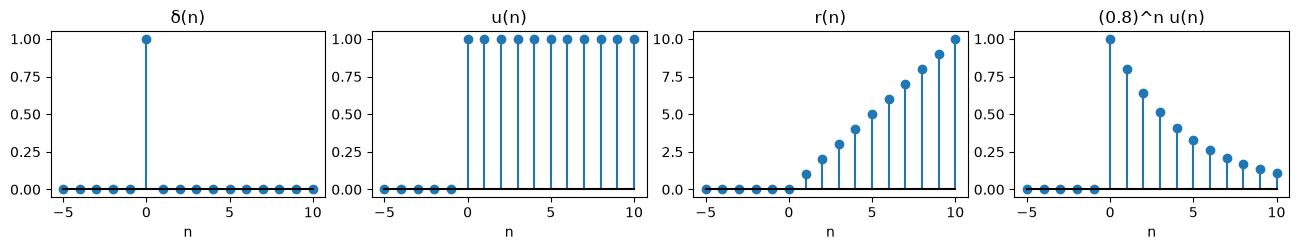

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step  = (n >= 0).astype(float)
ramp  = n * step
expo  = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

## Task 1.2 — Change the parameters

`cos(2πn/8)` repeats exactly because M = 8 is an integer; M = 7.5 does not.

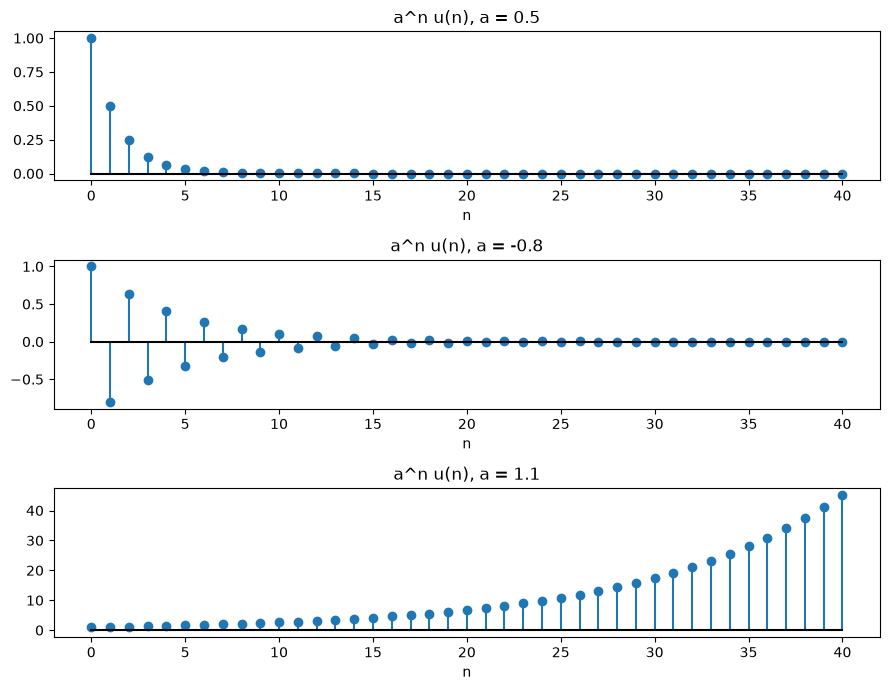

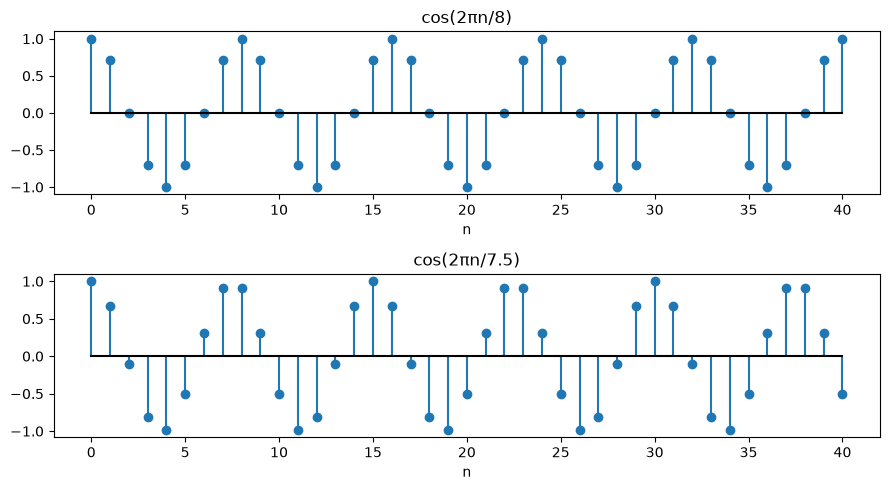

In [3]:
n = np.arange(0, 41)

fig, axes = plt.subplots(3, 1, figsize=(9, 7))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    x = (a**n) * (n >= 0).astype(float)
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a^n u(n), a = {a}")
    ax.set_xlabel("n")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(9, 5))
for ax, M in zip(axes, [8, 7.5]):
    ax.stem(n, np.cos(2*np.pi*n/M), basefmt="k-")
    ax.set_title(f"cos(2πn/{M})")
    ax.set_xlabel("n")
plt.tight_layout()
plt.show()

## Task 1.3 — Working with audio

fs = 44100 Hz, duration = 6.99 s, samples = 308202


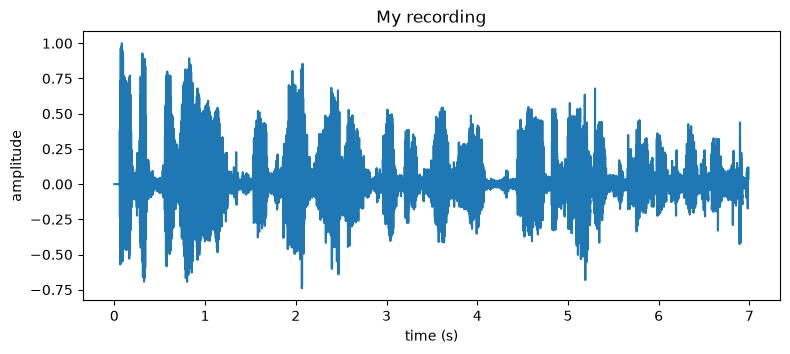

In [4]:
import os
from IPython.display import Audio

fname = "my_voice1.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

Audio(x, rate=fs)

## Analysis questions

1. My recording was sampled at 44100 Hz, so one minute of mono audio needs
   44100 × 60 = 2,646,000 samples (numbers). If each sample is 16-bit,
   that is about 5.29 MB. My own recording was 6.99 s and had 308202 samples.

2. I used a stem plot because x(n) exists only at integer values of n.
   A continuous line would imply values between samples, which do not exist.

3. For a = 1.1 the exponential grows as n increases, so h(n) is not
   absolutely summable. The system is therefore not BIBO stable.

## Task 1.4 — The same in Octave (optional)

Skipped: GNU Octave is not installed on this computer. This task is optional
in the manual; Tasks 1.1-1.3 were completed in Python/Jupyter.

## Task 1.5 — Repository and submission

Repository: https://github.com/Kazaura7/COU07506-labs-240242408359

## AI-use statement

AI tools used: opencode.
Used for: help with Task 1.3 code and checking my analysis answers.
Verified with my_voice1.wav: 44100 Hz, 6.99 s, 308202 samples.
I confirm I understand and can explain all submitted code.
